# 🔗 Build an Augmented LLM with Tools in LangGraph

## Learning Objectives
In this notebook, you will learn:
1. **Understand tool augmentation** - Why give an LLM tools at all
2. **Use LangGraph's `ToolNode`** - Let the graph execute tool calls instead of your own loop
3. **Route with `tools_condition`** - Send the flow to the tools only when the LLM asked for them
4. **See the limit of an augmented LLM** - Why this graph is not yet an agent

## Prerequisites
- Defining tools and binding them with `bind_tools()` — covered in `01_defining_tools` and `02_tool_calling_manual_loop`
- Dependencies installed with `uv sync` at the repository root
- `OPENAI_API_KEY` and `TAVILY_API_KEY` in the project-root `.env`

## Why Augment LLMs with Tools?

LLMs have inherent limitations:
- **Knowledge cutoff** - Training data has a date limit
- **No real-time access** - Can't fetch current information
- **Limited computation** - Struggle with complex math
- **No external actions** - Can't send emails, query databases, etc.

**Tools** extend LLM capabilities by allowing them to:
- Search the web for current information
- Execute calculations accurately
- Query databases and APIs
- Perform actions in the real world

## What We're Building

```
┌─────────────────────────────────────────────────────────────────┐
│               AUGMENTED LLM ARCHITECTURE                        │
├─────────────────────────────────────────────────────────────────┤
│                                                                  │
│  User Query ──► [LLM + Tools] ──►  Decision:                    │
│                                     ├─► Answer directly         │
│                                     └─► Call a tool             │
│                                                                  │
│  Tools Available:                                                │
│    • search_web: Search the internet for information            │
│    • (more tools can be added)                                  │
│                                                                  │
└─────────────────────────────────────────────────────────────────┘
```

We already know Tools help the LLM interact with external sources of information like web search.

Augmented LLM with Search Tool: Here we will build a simple augmented LLM using the capabilities of Tavily Search as a tool to allow the LLM to fetch relevant information from the web when necessary.

![](https://i.imgur.com/5r015dw.png)

---
## 📦 Step 1: Environment Setup

Load the API keys from the project-root `.env` and import the shared LLM factory.

In [1]:
# ============================================================================
# ENVIRONMENT SETUP: Load API keys and the LLM factory
# ============================================================================
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))

# Import the shared LLM factory
from aied_helpers import get_openai_llm

print("Setup complete! Ready to build an augmented LLM.")

Setup complete! Ready to build an augmented LLM.


---
## 🧩 Part 1: Define the State

For tool-augmented LLMs, the state needs to track messages which may include:
- **HumanMessage** - User's input query
- **AIMessage** - LLM's response (may contain tool calls)
- **ToolMessage** - Results returned from tool execution

The `add_messages` reducer ensures all these are preserved in order.

Let's use the `TypedDict` class from python's `typing` module as our schema, which provides type hints for the keys.

In [2]:
# ============================================================================
# DEFINING STATE FOR TOOL-AUGMENTED LLM
# ============================================================================
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    """
    State schema for tool-augmented LLM.
    
    The messages list will contain a mix of:
    - HumanMessage: User queries
    - AIMessage: LLM responses (possibly with tool_calls)
    - ToolMessage: Results from tool execution
    
    Using add_messages reducer to preserve the full interaction history.
    """
    messages: Annotated[list, add_messages]

---
## 🔧 Part 2: Give the LLM a Tool

The same two moves as in notebook 02: define a tool with `@tool` (its docstring tells the LLM *what* it does and *when* to use it) and attach it with `bind_tools()`. What is new starts in Part 3: instead of executing the tool call ourselves, we let a LangGraph node do it.

Here we define a web-search tool backed by Tavily and bind it to the LLM.

In [3]:
# ============================================================================
# CREATING AND BINDING TOOLS TO THE LLM
# ============================================================================
from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper
from langchain_core.tools import tool

# -----------------------------------------------------------------------------
# Step 1: Initialize the base LLM
# -----------------------------------------------------------------------------
llm = get_openai_llm(model="gpt-4o-mini")

# -----------------------------------------------------------------------------
# Step 2: Create a search tool using Tavily
# Tavily is a search API designed for AI applications
# -----------------------------------------------------------------------------
tavily_search = TavilySearchAPIWrapper()

@tool
def search_web(query: str, num_results: int = 5):
    """
    Search the web for a query. Useful for general information or general news.
    
    This docstring is CRITICAL - it tells the LLM:
    - WHAT the tool does (search the web)
    - WHEN to use it (for general info/news)
    
    Args:
        query: The search query to look up
        num_results: Number of results to return (default 5)
        
    Returns:
        Search results from the web
    """
    print(f"  [Tool] Searching web for: '{query}'")
    results = tavily_search.raw_results(
        query=query,
        max_results=num_results,
        search_depth='advanced',
        include_raw_content=True
    )
    return results

# -----------------------------------------------------------------------------
# Step 3: Create the tools list and bind to LLM
# bind_tools() creates an "augmented" LLM that knows about these tools
# -----------------------------------------------------------------------------
tools = [search_web]  # List of all available tools

# Bind tools to the LLM
# This creates a new LLM that can decide to call tools when needed
llm_with_tools = llm.bind_tools(tools=tools)

print(f"LLM augmented with {len(tools)} tool(s): {[t.name for t in tools]}")

LLM augmented with 1 tool(s): ['search_web']


/var/folders/16/l0pt1ckj4hg1jzr4894_3f340000gn/T/ipykernel_20437/252570322.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper


---
## 🕸️ Part 3: Create the Graph with the Augmented LLM

### Key LangGraph Components for Tool Use

| Component | Purpose |
|-----------|---------|
| **ToolNode** | Pre-built node that executes tool calls |
| **tools_condition** | Pre-built routing function for tool decisions |

### How it Works

1. **LLM Node** receives user message and returns:
   - Direct response (no tools needed), OR
   - Tool call request (tools needed)

2. **tools_condition** checks the LLM response:
   - If `tool_calls` present → route to ToolNode
   - If no `tool_calls` → route to END

3. **ToolNode** executes the requested tools and returns results

```
                    ┌─────────────────┐
                    │ tool_calling_llm│
                    └────────┬────────┘
                             │
                    ┌────────▼────────┐
                    │ tools_condition │
                    └────────┬────────┘
               ┌─────────────┴─────────────┐
               │                           │
               ▼                           ▼
         ┌──────────┐                 ┌─────────┐
         │  tools   │                 │   END   │
         │(ToolNode)│                 │         │
         └──────────┘                 └─────────┘
```

![](https://i.imgur.com/5r015dw.png)

Augmented LLM graph compiled!
Graph structure:


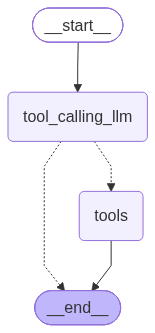

In [4]:
# ============================================================================
# BUILD THE AUGMENTED LLM GRAPH
# ============================================================================
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display

# -----------------------------------------------------------------------------
# Step 1: Define the LLM node with tool-calling capability
# This node calls our tool-augmented LLM
# -----------------------------------------------------------------------------
def tool_calling_llm(state: State) -> State:
    """
    Node that calls the tool-augmented LLM.
    
    The LLM will:
    1. Analyze the user's message
    2. Decide if tools are needed
    3. Return either:
       - A direct response (AIMessage with content)
       - A tool call request (AIMessage with tool_calls)
    """
    current_messages = state["messages"]
    response = llm_with_tools.invoke(current_messages)
    return {"messages": [response]}

# -----------------------------------------------------------------------------
# Step 2: Build the graph
# -----------------------------------------------------------------------------
builder = StateGraph(State)

# Add the LLM node (makes decisions about tool use)
builder.add_node("tool_calling_llm", tool_calling_llm)

# Add the ToolNode (executes tools when called)
# ToolNode is a pre-built node that:
# - Extracts tool calls from the AIMessage
# - Executes each tool with provided arguments
# - Returns ToolMessage(s) with results
builder.add_node("tools", ToolNode(tools=tools))

# Entry point
builder.add_edge(START, "tool_calling_llm")

# -----------------------------------------------------------------------------
# Step 3: Add conditional routing based on tool_calls
# tools_condition is a pre-built function that:
# - Returns "tools" if the LLM response has tool_calls
# - Returns END if no tool_calls (direct response)
# -----------------------------------------------------------------------------
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition  # Built-in routing: checks for tool_calls in response
    # Automatically routes to "tools" or END
)

# After tools execute, we're done (for this simple example)
builder.add_edge("tools", END)

# Compile
graph = builder.compile()

print("Augmented LLM graph compiled!")
print("Graph structure:")
display(Image(graph.get_graph().draw_mermaid_png()))

In [5]:
# ============================================================================
# TEST 1: Query that DOESN'T need tools
# ============================================================================
# Simple factual question - LLM can answer from training data
# Expected: Direct response, no tool calls

print("=" * 70)
print("TEST 1: Simple query (no tools needed)")
print("Query: 'Explain AI in 2 bullets'")
print("=" * 70)

user_input = "Explain AI in 2 bullets"

print("\nStreaming graph execution:\n")
for event in graph.stream({"messages": user_input},
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

print("\n" + "=" * 70)
print("Observation: LLM answered directly without calling any tools")
print("=" * 70)

TEST 1: Simple query (no tools needed)
Query: 'Explain AI in 2 bullets'

Streaming graph execution:

================================ Human Message =================================

Explain AI in 2 bullets


================================== Ai Message ==================================

- **Definition**: Artificial Intelligence (AI) refers to the simulation of human intelligence in machines that are programmed to think, learn, and perform tasks that typically require human cognitive functions, such as problem-solving, understanding language, and recognizing patterns.

- **Applications**: AI is utilized across various fields, including healthcare (for diagnostics and personalized medicine), finance (for fraud detection and algorithmic trading), autonomous vehicles, customer service (via chatbots), and many more, enhancing efficiency and decision-making processes.

Observation: LLM answered directly without calling any tools


In [6]:
# ============================================================================
# TEST 2: Query that NEEDS tools (current information)
# ============================================================================
# This question requires current/real-time information
# Expected: LLM calls search_web tool, results returned

print("=" * 70)
print("TEST 2: Query requiring current information (tools needed)")
print("Query: 'What is the latest news on OpenAI product releases'")
print("=" * 70)

user_input = "What is the latest news on OpenAI product releases"

print("\nStreaming graph execution:\n")
for event in graph.stream({"messages": user_input},
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

print("\n" + "=" * 70)
print("Observation: LLM decided to use the search_web tool!")
print("The flow was: LLM → tool call → ToolNode executes → Results returned")
print("=" * 70)

TEST 2: Query requiring current information (tools needed)
Query: 'What is the latest news on OpenAI product releases'

Streaming graph execution:

================================ Human Message =================================

What is the latest news on OpenAI product releases


================================== Ai Message ==================================
Tool Calls:
  search_web (call_xwk06FJddIzS1CAHlzYVt1hC)
 Call ID: call_xwk06FJddIzS1CAHlzYVt1hC
  Args:
    query: OpenAI product releases news
    num_results: 5
  [Tool] Searching web for: 'OpenAI product releases news'


================================= Tool Message =================================
Name: search_web

{"query": "OpenAI product releases news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://openai.com/research/index/release", "title": "OpenAI Research | Release", "content": "Product\n\nJul 9, 2026\n\nGPT-5.6: Frontier intelligence that scales with your ambition More intelligence from every token, stronger performance per dollar, and more capability on demand for your hardest work.\n\nProduct\n\nJul 8, 2026\n\nIntroducing GPT-Live A new generation of voice models for natural human-AI interaction, now powering ChatGPT Voice.\n\nProduct\n\nJun 26, 2026\n\nPreviewing GPT-5.6 Sol: a next-generation model OpenAI previews GPT-5.6 Sol, a next-generation model with stronger capabilities in coding, science, and cybersecurity, paired with its most advanced safety stack.\n\nResearch\n\nJun 4, 2026\n\nDreaming: Better memory for a more helpful ChatGPT ChatGPT 

---
## 📝 Summary

In this notebook, we learned:

### What We Built
An augmented LLM that can:
- Decide when to use external tools
- Execute web searches for current information
- Return results to the user

### Key Concepts

| Concept | Description |
|---------|-------------|
| **@tool / bind_tools()** | Define a tool and attach it to the LLM (notebooks 01–02) |
| **ToolNode** | Pre-built node that executes tool calls |
| **tools_condition** | Pre-built routing based on tool_calls |

### The Tool-Use Pattern

```
1. LLM receives query
2. LLM decides: Can I answer directly, or do I need tools?
3a. Direct answer → Return response → END
3b. Need tools → Generate tool_call → ToolNode executes → Return results
```

### Important Limitation
**This version has no feedback loop!** The tool results go to END, not back to the LLM.
This means:
- The LLM can't process tool results
- No human-readable response from tool outputs
- Can't chain multiple tool calls

**Solution**: In the next notebook, `04_tool_loop_errors_and_evaluation`, one edge changes — `tools → LLM` instead of `tools → END` — and the loop closes.

### Next Steps
Build a complete **Tool-Use AI Agent** with feedback loops that:
- Processes tool results with the LLM
- Generates human-readable responses
- Can call multiple tools in sequence